# 01 — FD001 Statistical Analysis

**Project:** NASA C-MAPSS Remaining Useful Life (RUL) prediction — Part 1, statistics only.
**Scope:** this notebook performs structural checks, descriptive statistics and exploratory charts on the FD001 **training** data only. **No prediction models are trained here.**

## What this notebook uses

| Item | Status |
|---|---|
| `notebooks/data/train_FD001.csv` | Used — the only dataset analysed |
| `notebooks/data/data_dictionary.csv` | Used — column meanings |
| `notebooks/data/validation_summary.csv` | Used — previously recorded checks, independently re-verified below |
| `NASA_CMAPSS_Dataset_and_Sensor_Guide.pdf` | Available in the project root; sensor meanings quoted from it |
| `README.md` (project root) | **Not usable — the file exists but is empty (0 bytes)** |
| `NASA_CMAPSS_RUL_Supervised_Regression_Project_Proposal.pdf` | **Missing — this file was not found in the project.** No invented substitute is used |

## What this notebook deliberately does NOT use

`test_FD001.csv`, `RUL_FD001.csv` and `test_last_cycle_FD001_labeled.csv` are **kept untouched** for final model evaluation. They are never opened here.

## Key conventions used throughout

- **One row = one engine at one recorded operating cycle.** 20,631 rows therefore represent repeated observations of 100 engines, not 20,631 independent engines.
- The data are **simulated** engine histories from NASA C-MAPSS (not measurements from a real aircraft fleet).
- **RUL is measured in operating cycles** — not hours, days or percentages. `RUL = 40` means 40 recorded cycles remain until the simulated failure point.
- FD001 has **one operating condition and one degradation mode** (HPC). FD002–FD004 are separate scenarios and are **not merged** into this analysis.
- All exploratory statistics and charts use an **80% engine-level development partition**; the remaining 20% of engines are held out as a first validation partition. Every output is labelled with its population, engine count and row count.
- Everything is reproducible with **seed = 42**.

The notebook can be run from the project root **or** from the `notebooks` folder; paths are detected automatically.

---

## 0. Setup

This cell imports the libraries and creates the configuration used by every later cell: library versions, the data folder discovered relative to the current working directory, a fixed random seed, plot styling, and a running list of files that were actually read (checked in the final verification cell).

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42


def find_data_dir():
    start = Path.cwd().resolve()
    for base in [start, *start.parents]:
        for candidate in (base / "notebooks" / "data", base / "data"):
            if (candidate / "train_FD001.csv").is_file():
                return candidate
    raise FileNotFoundError(
        "Could not find train_FD001.csv. Run this notebook from the project root "
        "or from the notebooks folder."
    )


DATA_DIR = find_data_dir()
FILES_USED = []

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.titlesize": 12,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

print("Working directory :", Path.cwd())
print("Data directory    :", DATA_DIR)
print("Random seed       :", SEED)
print("pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Working directory : c:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks
Data directory    : C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data
Random seed       : 42
pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2


## 1. Load the training data and supporting files

Only `train_FD001.csv` is loaded as data. The dictionary and the validation summary are loaded as documentation if present.

In [2]:
train_path = DATA_DIR / "train_FD001.csv"
train = pd.read_csv(train_path)
FILES_USED.append(train_path.name)

dictionary_path = DATA_DIR / "data_dictionary.csv"
validation_path = DATA_DIR / "validation_summary.csv"

dictionary = pd.read_csv(dictionary_path) if dictionary_path.is_file() else None
validation = pd.read_csv(validation_path) if validation_path.is_file() else None
if dictionary is not None:
    FILES_USED.append(dictionary_path.name)
if validation is not None:
    FILES_USED.append(validation_path.name)

print("Loaded:", train_path.name, "| shape:", train.shape)
print("Data dictionary available   :", dictionary is not None)
print("Validation summary available:", validation is not None)

duplicate_copies = sorted(
    p.name for p in DATA_DIR.iterdir()
    if p.is_file() and re.search(r"\(\d+\)", p.name)
)
print("Duplicate 'name (1).csv' style copies found:", duplicate_copies if duplicate_copies else "none")

Loaded: train_FD001.csv | shape: (20631, 27)
Data dictionary available   : True
Validation summary available: True
Duplicate 'name (1).csv' style copies found: none


### Structure check against the expected FD001 shape

The training file is expected to hold **20,631 rows, 100 engines and 27 columns**. This cell reports discrepancies instead of silently forcing the data to match. It also shows the first five sample rows and the column dictionary.

In [3]:
expected = {"rows": 20631, "engines": 100, "columns": 27}
actual = {
    "rows": int(train.shape[0]),
    "engines": int(train["engine_id"].nunique()),
    "columns": int(train.shape[1]),
}

structure = pd.DataFrame({
    "Expected": pd.Series(expected),
    "Actual": pd.Series(actual),
})
structure["Match"] = structure["Expected"] == structure["Actual"]
display(structure)

if not structure["Match"].all():
    print("NOTE: discrepancies exist between the expected and actual FD001 structure; "
          "they are reported above and NOT corrected by modifying the data.")
else:
    print("Structure matches the documented FD001 training file exactly.")

print("First five rows of the training file (population: full training file, "
      f"{train['engine_id'].nunique()} engines, {len(train)} rows):")
display(train.head(5))

if dictionary is not None:
    print("Column dictionary (data_dictionary.csv):")
    display(dictionary)

,Expected,Actual,Match
rows,20631,20631,True
engines,100,100,True
columns,27,27,True


Structure matches the documented FD001 training file exactly.
First five rows of the training file (population: full training file, 100 engines, 20631 rows):


,engine_id,cycle,operating_setting_1,operating_setting_2,operating_setting_3,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,sensor_09,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


Column dictionary (data_dictionary.csv):


,column,type,meaning
0,engine_id,integer,Group identifier within subset and split. Exclude from model predictors.
1,cycle,integer,"Observed engine operating cycle, starting at 1. Potential predictor."
2,operating_setting_1,numeric,Original operating-setting value. Potential predictor.
3,operating_setting_2,numeric,Original operating-setting value. Potential predictor.
4,operating_setting_3,numeric,Original operating-setting value. Potential predictor.
5,sensor_01,numeric,Original sensor measurement 1. Generic source-order name. Potential predictor.
6,sensor_02,numeric,Original sensor measurement 2. Generic source-order name. Potential predictor.
7,sensor_03,numeric,Original sensor measurement 3. Generic source-order name. Potential predictor.
8,sensor_04,numeric,Original sensor measurement 4. Generic source-order name. Potential predictor.
9,sensor_05,numeric,Original sensor measurement 5. Generic source-order name. Potential predictor.


## A. Dataset overview and quality-check table

**Purpose.** Before any statistics, we confirm the file is structurally trustworthy: no missing values, no duplicated engine–cycle keys, consistent cycle numbering and a correctly computed RUL target. If a critical check failed, further analysis would be unreliable and the notebook stops with an explanation.

Checks are run on the **full training file** (all 100 engines, 20,631 rows).

In [5]:
n_rows, n_engines, n_cols = train.shape[0], train["engine_id"].nunique(), train.shape[1]
print(f"[Full training file] engines: {n_engines} | rows: {n_rows} | columns: {n_cols}")

checks = []

checks.append((
    "File structure (20,631 rows / 100 engines / 27 columns)",
    "PASS" if (n_rows, n_engines, n_cols) == (20631, 100, 27) else "FAIL",
    0 if (n_rows, n_engines, n_cols) == (20631, 100, 27) else 1,
    "Matches the documented FD001 training file.",
))

non_numeric = train.select_dtypes(exclude=[np.number]).columns.tolist()
checks.append((
    "All columns numeric",
    "PASS" if not non_numeric else "FAIL",
    len(non_numeric),
    "No text or mixed-type columns." if not non_numeric else f"Unexpected columns: {non_numeric}",
))

n_missing = int(train.isna().sum().sum())
checks.append((
    "Missing values",
    "PASS" if n_missing == 0 else "FAIL",
    n_missing,
    "Every cell is filled." if n_missing == 0 else "Missing cells would need treatment.",
))

numeric_block = train.select_dtypes(include=[np.number])
n_nonfinite = int((~np.isfinite(numeric_block)).sum().sum())
checks.append((
    "Non-finite numeric values (inf / -inf / NaN)",
    "PASS" if n_nonfinite == 0 else "FAIL",
    n_nonfinite,
    "All numeric values are finite.",
))

n_dup_rows = int(train.duplicated().sum())
checks.append((
    "Exact duplicate rows",
    "PASS" if n_dup_rows == 0 else "FAIL",
    n_dup_rows,
    "No identical row appears twice." if n_dup_rows == 0 else "Duplicates would suggest a merge problem.",
))

n_dup_keys = int(train.duplicated(["engine_id", "cycle"]).sum())
checks.append((
    "Duplicate (engine_id, cycle) keys",
    "PASS" if n_dup_keys == 0 else "FAIL",
    n_dup_keys,
    "Each engine–cycle combination appears exactly once." if n_dup_keys == 0
    else "Duplicate keys would make cycle-based analysis ambiguous.",
))

id_cycle_int = bool(train["engine_id"].dtype.kind == "i" and train["cycle"].dtype.kind == "i")
id_cycle_positive = bool((train["engine_id"] > 0).all() and (train["cycle"] > 0).all())
checks.append((
    "engine_id and cycle are positive integers",
    "PASS" if (id_cycle_int and id_cycle_positive) else "FAIL",
    0 if (id_cycle_int and id_cycle_positive) else 1,
    "IDs and cycles are usable as integer keys.",
))

grouped_cycles = train.groupby("engine_id")["cycle"]
n_bad_start = int((grouped_cycles.min() != 1).sum())
checks.append((
    "Every engine's cycles start at 1",
    "PASS" if n_bad_start == 0 else "FAIL",
    n_bad_start,
    "All 100 engines begin their recorded history at cycle 1." if n_bad_start == 0 else "Some engines start later.",
))

gap_flags = grouped_cycles.apply(lambda s: (s.diff().dropna() != 1).any())
n_gap_engines = int(gap_flags.sum())
checks.append((
    "Cycles continue without gaps",
    "PASS" if n_gap_engines == 0 else "FAIL",
    n_gap_engines,
    "Recorded cycles are contiguous for every engine." if n_gap_engines == 0
    else "Missing cycles inside histories would need investigation.",
))

n_negative_rul = int((train["RUL"] < 0).sum())
checks.append((
    "RUL is never negative",
    "PASS" if n_negative_rul == 0 else "FAIL",
    n_negative_rul,
    "RUL ranges from 0 upward." if n_negative_rul == 0 else "Negative RUL is impossible.",
))

max_cycle_per_engine = train.groupby("engine_id")["cycle"].transform("max")
rul_mismatch = int((train["RUL"] != max_cycle_per_engine - train["cycle"]).sum())
checks.append((
    "RUL = engine maximum cycle - current cycle",
    "PASS" if rul_mismatch == 0 else "FAIL",
    rul_mismatch,
    "The target follows the documented construction rule exactly." if rul_mismatch == 0
    else "Target definition differs from the documented rule.",
))

last_rows = train.groupby("engine_id").tail(1)
n_bad_last = int((last_rows["RUL"] != 0).sum())
checks.append((
    "Final training row of every engine has RUL = 0",
    "PASS" if n_bad_last == 0 else "FAIL",
    n_bad_last,
    "Each engine's recorded history ends at its simulated failure point." if n_bad_last == 0
    else "Some engines do not end at failure.",
))

quality = pd.DataFrame(checks, columns=["Check", "Result", "Issue count", "Meaning"])
display(quality)

critical_issues = n_dup_keys + n_missing + n_nonfinite + rul_mismatch
if critical_issues > 0:
    raise SystemExit(
        "STOP: critical data-quality issue(s) detected "
        f"({critical_issues} problem(s), see table above). "
        "Further statistical analysis would be unreliable until these are resolved."
    )
print("All quality checks passed. No critical issue found; the analysis continues.")

[Full training file] engines: 100 | rows: 20631 | columns: 27


,Check,Result,Issue count,Meaning
0,"File structure (20,631 rows / 100 engines / 27 columns)",PASS,0,Matches the documented FD001 training file.
1,All columns numeric,PASS,0,No text or mixed-type columns.
2,Missing values,PASS,0,Every cell is filled.
3,Non-finite numeric values (inf / -inf / NaN),PASS,0,All numeric values are finite.
4,Exact duplicate rows,PASS,0,No identical row appears twice.
5,"Duplicate (engine_id, cycle) keys",PASS,0,Each engine–cycle combination appears exactly once.
6,engine_id and cycle are positive integers,PASS,0,IDs and cycles are usable as integer keys.
7,Every engine's cycles start at 1,PASS,0,All 100 engines begin their recorded history at cycle 1.
8,Cycles continue without gaps,PASS,0,Recorded cycles are contiguous for every engine.
9,RUL is never negative,PASS,0,RUL ranges from 0 upward.


All quality checks passed. No critical issue found; the analysis continues.


### Independent re-verification of `validation_summary.csv`

The summary file records past checks for FD001. This cell recomputes the same quantities directly from the raw CSV and compares them. (One recorded item, `exact_csv_roundtrip`, compares against the original NASA download, which is not present here; the remaining fields are re-verified.)

In [6]:
input_cols = [c for c in train.columns if c not in ("engine_id", "RUL")]
full_constants = sorted(c for c in input_cols if train[c].nunique() == 1)

recorded = validation.loc[validation["subset"] == "FD001"].iloc[0] if validation is not None else None

if recorded is not None:
    recomputed = {
        "train_rows": len(train),
        "train_engines": train["engine_id"].nunique(),
        "train_columns_including_target": train.shape[1],
        "missing_numeric_values": int(train.isna().sum().sum()),
        "duplicate_engine_cycle_keys": int(train.duplicated(["engine_id", "cycle"]).sum()),
        "constant_training_columns": "; ".join(full_constants),
    }
    rows = []
    for field, value in recomputed.items():
        recorded_value = recorded[field]
        match = str(recorded_value) == str(value)
        rows.append({"Field": field, "Recorded": recorded_value,
                     "Recomputed": value, "Match": "YES" if match else "NO"})
    display(pd.DataFrame(rows))
    print("Roundtrip check against original NASA download: not re-verifiable here "
          "(original download not present); every other recorded check was reproduced.")
else:
    print("validation_summary.csv not available; independent checks above still apply.")

,Field,Recorded,Recomputed,Match
0,train_rows,20631,20631,YES
1,train_engines,100,100,YES
2,train_columns_including_target,27,27,YES
3,missing_numeric_values,0,0,YES
4,duplicate_engine_cycle_keys,0,0,YES
5,constant_training_columns,operating_setting_3; sensor_01; sensor_05; sensor_10; sensor_16; sensor_18; sensor_19,operating_setting_3; sensor_01; sensor_05; sensor_10; sensor_16; sensor_18; sensor_19,YES


Roundtrip check against original NASA download: not re-verifiable here (original download not present); every other recorded check was reproduced.


## 2. Engine-level development / validation split

**Why.** Cycles from the same engine are strongly related. A random **row** split would let later cycles of one engine appear in both partitions, leaking information. We therefore split **by engine**: 80% of engines (development) for the statistics and charts in this notebook, 20% of engines (validation) reserved for later model checking.

Because an engine's rows are never separated, every statistic below is either clearly engine-averaged or clearly labelled as row-level over the development partition. Split is reproducible with seed 42.

In [7]:
split_rng = np.random.default_rng(SEED)
all_engine_ids = np.sort(train["engine_id"].unique())
shuffled_ids = split_rng.permutation(all_engine_ids)

dev_count = int(round(0.80 * len(shuffled_ids)))
dev_ids = np.sort(shuffled_ids[:dev_count])
val_ids = np.sort(shuffled_ids[dev_count:])

dev = train[train["engine_id"].isin(dev_ids)].reset_index(drop=True)
val = train[train["engine_id"].isin(val_ids)].reset_index(drop=True)

assert set(dev_ids).isdisjoint(val_ids), "Engine overlap between partitions!"
assert len(dev) + len(val) == len(train)
assert dev["engine_id"].nunique() == len(dev_ids)
assert val["engine_id"].nunique() == len(val_ids)
assert set(dev["engine_id"]).isdisjoint(set(val["engine_id"]))


def population_label(name, frame):
    return f"[{name}] engines: {frame['engine_id'].nunique()} | rows: {len(frame)}"


def lifetime_of(frame):
    return frame.groupby("engine_id")["cycle"].max()


dev_lifetime = lifetime_of(dev)
val_lifetime = lifetime_of(val)

split_table = pd.DataFrame([
    {
        "Partition": "Development (80%)",
        "Engine IDs": f"{dev_ids[0]}–{dev_ids[-1]} (sorted, {len(dev_ids)} engines)",
        "Engines": len(dev_ids),
        "Rows": len(dev),
        "Share of rows": f"{len(dev) / len(train):.1%}",
        "Mean RUL": round(dev["RUL"].mean(), 1),
        "Lifetime min–max (cycles)": f"{dev_lifetime.min()}–{dev_lifetime.max()}",
    },
    {
        "Partition": "Validation (20%)",
        "Engine IDs": f"{val_ids[0]}–{val_ids[-1]} (sorted, {len(val_ids)} engines)",
        "Engines": len(val_ids),
        "Rows": len(val),
        "Share of rows": f"{len(val) / len(train):.1%}",
        "Mean RUL": round(val["RUL"].mean(), 1),
        "Lifetime min–max (cycles)": f"{val_lifetime.min()}–{val_lifetime.max()}",
    },
])
display(split_table)

print(population_label("Development", dev))
print(population_label("Validation", val))
print("Overlap between development and validation engine sets:",
      set(dev_ids) & set(val_ids) or "none")
print("Seed used:", SEED)

,Partition,Engine IDs,Engines,Rows,Share of rows,Mean RUL,Lifetime min–max (cycles)
0,Development (80%),"1–100 (sorted, 80 engines)",80,16527,80.1%,108.0,128–362
1,Validation (20%),"7–91 (sorted, 20 engines)",20,4104,19.9%,107.1,135–313


[Development] engines: 80 | rows: 16527
[Validation] engines: 20 | rows: 4104
Overlap between development and validation engine sets: none
Seed used: 42


## B. Descriptive statistics (development partition)

**Purpose.** Summaries of central tendency and spread for every measurement column, so that later modelling choices (scaling, feature selection) are informed. `engine_id` is excluded — it is an identifier, not a measurement.

**Important caveat:** these are **row-level** summaries. Engines with longer recorded histories contribute more rows, so the table over-represents long-lived engines. Standard deviations are in each column's own raw units — a larger standard deviation does **not** automatically mean a more important sensor.

In [8]:
print(population_label("Development (80%)", dev))

measure_cols = [c for c in train.columns if c != "engine_id"]
desc = pd.DataFrame({
    "count": dev[measure_cols].count(),
    "mean": dev[measure_cols].mean(),
    "median": dev[measure_cols].median(),
    "std": dev[measure_cols].std(),
    "min": dev[measure_cols].min(),
    "25%": dev[measure_cols].quantile(0.25),
    "75%": dev[measure_cols].quantile(0.75),
    "max": dev[measure_cols].max(),
})
desc["IQR"] = desc["75%"] - desc["25%"]
desc["unique values"] = dev[measure_cols].nunique()
display(desc.round(4))

[Development (80%)] engines: 80 | rows: 16527


,count,mean,median,std,min,25%,75%,max,IQR,unique values
cycle,16527,108.9853,104.0000,69.1340,1.0000,52.0000,157.0000,362.0000,105.0000,362
operating_setting_1,16527,-0.0000,0.0000,0.0022,-0.0087,-0.0015,0.0014,0.0087,0.0030,155
operating_setting_2,16527,0.0000,0.0000,0.0003,-0.0006,-0.0002,0.0003,0.0006,0.0005,13
operating_setting_3,16527,100.0000,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,0.0000,1
sensor_01,16527,518.6700,518.6700,0.0000,518.6700,518.6700,518.6700,518.6700,0.0000,1
sensor_02,16527,642.6771,642.6400,0.5010,641.2100,642.3200,643.0000,644.5300,0.6800,309
sensor_03,16527,1590.4756,1590.0300,6.1525,1571.0400,1586.1900,1594.2900,1616.9100,8.1000,2902
sensor_04,16527,1408.8854,1407.9800,8.9774,1385.1900,1402.3400,1414.4600,1441.4900,12.1200,3870
sensor_05,16527,14.6200,14.6200,0.0000,14.6200,14.6200,14.6200,14.6200,0.0000,1
sensor_06,16527,21.6098,21.6100,0.0014,21.6000,21.6100,21.6100,21.6100,0.0000,2


**Reading of section B.** All 25 candidate inputs cover sensible numeric ranges (for example `sensor_04` spans 1385–1441 in its raw units, `sensor_09` spans 9022–9245). The scales differ by orders of magnitude (e.g. `sensor_01` ≈ 518.7 vs `sensor_16` ≈ 0.03), which is expected for a mix of temperatures, pressures, speeds and ratios — later models will need scaling or scale-invariant methods. Several columns show the same value nearly everywhere (see section C). Because rows are weighted by engine lifetime, the row-level means sit slightly differently from engine-level views used later (e.g. section D).

## C. Constant and nearly constant columns (development partition only)

**Purpose.** A column with a single value carries no information and breaks correlation calculations (division by zero variance). Constant columns must be identified **using the development partition only**, so that the validation partition stays uncontaminated.

Classification rule (transparent and reproducible):

- **Exactly constant** — one unique value.
- **Nearly constant** — more than one value, but the most frequent value covers ≥ 98% of the development rows.
- **Varying** — everything else.

The rule uses the *share* of the dominant value, never the magnitude of the numbers: small values such as `operating_setting_1` (~0.000) are **not** flagged merely because they are small. The original dataframes are left unchanged; constant columns are simply excluded where correlations would be undefined.

In [9]:
print(population_label("Development (80%)", dev))

records = []
for c in input_cols:
    counts = dev[c].value_counts()
    n_unique = int(counts.size)
    top_value = counts.index[0]
    top_share = counts.iloc[0] / len(dev)
    if n_unique == 1:
        classification = "Exactly constant"
        treatment = "Drop from modelling — no information."
    elif n_unique <= 5 and top_share >= 0.98:
        classification = "Nearly constant"
        treatment = "Review before dropping — dominated by one value, but still varies."
    else:
        classification = "Varying"
        treatment = "Keep."
    records.append({
        "Column": c,
        "Unique-value count": n_unique,
        "Modal (most common) value": top_value,
        "Modal share": round(float(top_share), 4),
        "Classification": classification,
        "Suggested treatment": treatment,
    })

constant_table = pd.DataFrame(records)
flagged = constant_table[constant_table["Classification"] != "Varying"]
display(flagged.reset_index(drop=True))

n_const = int((constant_table["Classification"] == "Exactly constant").sum())
n_near = int((constant_table["Classification"] == "Nearly constant").sum())
n_var = int((constant_table["Classification"] == "Varying").sum())
print(f"Exactly constant: {n_const} | nearly constant: {n_near} | varying: {n_var}")

constant_cols = constant_table.loc[constant_table["Classification"] == "Exactly constant", "Column"].tolist()
nonconstant_inputs = constant_table.loc[constant_table["Classification"] != "Exactly constant", "Column"].tolist()
print("Constant columns (dropped from correlation work):", constant_cols)
print("Original training dataframe unchanged:", train.shape == (20631, 27),
      "| development dataframe unchanged:", len(dev) == 16527)

[Development (80%)] engines: 80 | rows: 16527


,Column,Unique-value count,Modal (most common) value,Modal share,Classification,Suggested treatment
0,operating_setting_3,1,100.00,1.0000,Exactly constant,Drop from modelling — no information.
1,sensor_01,1,518.67,1.0000,Exactly constant,Drop from modelling — no information.
2,sensor_05,1,14.62,1.0000,Exactly constant,Drop from modelling — no information.
3,sensor_06,2,21.61,0.9807,Nearly constant,"Review before dropping — dominated by one value, but still varies."
4,sensor_10,1,1.30,1.0000,Exactly constant,Drop from modelling — no information.
5,sensor_16,1,0.03,1.0000,Exactly constant,Drop from modelling — no information.
6,sensor_18,1,2388.00,1.0000,Exactly constant,Drop from modelling — no information.
7,sensor_19,1,100.00,1.0000,Exactly constant,Drop from modelling — no information.


Exactly constant: 7 | nearly constant: 1 | varying: 17
Constant columns (dropped from correlation work): ['operating_setting_3', 'sensor_01', 'sensor_05', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Original training dataframe unchanged: True | development dataframe unchanged: True


**Reading of section C.** Seven FD001 columns are **exactly constant** in the development partition (`operating_setting_3`, `sensor_01`, `sensor_05`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`) — these will be dropped for modelling. One column, **`sensor_06`, is nearly constant**: only two distinct values, with 21.61 covering about 98% of rows. It still varies, so it is retained in the analysis but should be reviewed before being used as a feature. No column was flagged just because its values are numerically small — `operating_setting_1` and `operating_setting_2` vary (small magnitudes, many distinct values) and stay in.

## D. Engine lifetime distribution (development partition)

**Purpose.** One lifetime value per engine: its maximum recorded cycle. This describes how much history is available per unit of analysis, which determines sensible rolling-window sizes and split strategy.

`Recorded trajectory length is not necessarily an engine's full real-world age from manufacture` — FD001 histories are simulation snapshots that end at the simulated failure point.

[Development (80%)] engines: 80 | rows: 16527


,Value
Number of engines,80.00
Minimum lifetime (cycles),128.00
Maximum lifetime (cycles),362.00
Mean lifetime (cycles),206.60
Median lifetime (cycles),199.00
Standard deviation (cycles),46.60
25th percentile (cycles),179.75
75th percentile (cycles),218.25
Interquartile range (cycles),38.50


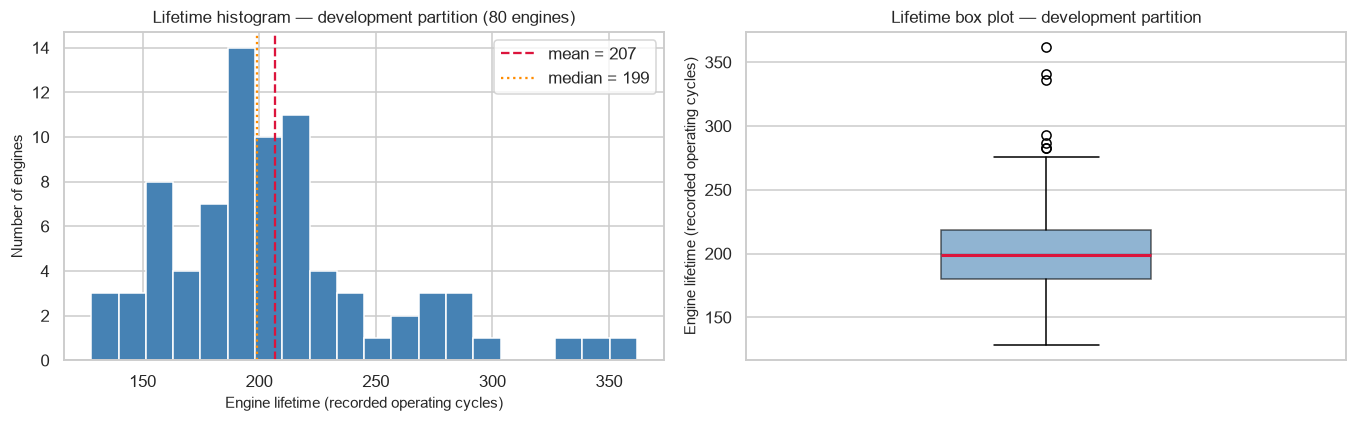

In [10]:
print(population_label("Development (80%)", dev))

life_stats = pd.Series({
    "Number of engines": len(dev_lifetime),
    "Minimum lifetime (cycles)": dev_lifetime.min(),
    "Maximum lifetime (cycles)": dev_lifetime.max(),
    "Mean lifetime (cycles)": round(dev_lifetime.mean(), 1),
    "Median lifetime (cycles)": dev_lifetime.median(),
    "Standard deviation (cycles)": round(dev_lifetime.std(), 1),
    "25th percentile (cycles)": dev_lifetime.quantile(0.25),
    "75th percentile (cycles)": dev_lifetime.quantile(0.75),
    "Interquartile range (cycles)": dev_lifetime.quantile(0.75) - dev_lifetime.quantile(0.25),
})
display(life_stats.to_frame("Value"))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
axes[0].hist(dev_lifetime, bins=20, color="steelblue", edgecolor="white")
axes[0].axvline(dev_lifetime.mean(), color="crimson", ls="--", lw=1.5,
                label=f"mean = {dev_lifetime.mean():.0f}")
axes[0].axvline(dev_lifetime.median(), color="darkorange", ls=":", lw=1.5,
                label=f"median = {dev_lifetime.median():.0f}")
axes[0].set_xlabel("Engine lifetime (recorded operating cycles)")
axes[0].set_ylabel("Number of engines")
axes[0].set_title(f"Lifetime histogram — development partition ({len(dev_lifetime)} engines)")
axes[0].legend()

axes[1].boxplot(dev_lifetime, orientation="vertical", patch_artist=True, widths=0.35,
                boxprops=dict(facecolor="steelblue", alpha=0.6),
                medianprops=dict(color="crimson", lw=2))
axes[1].set_ylabel("Engine lifetime (recorded operating cycles)")
axes[1].set_xticks([])
axes[1].set_title("Lifetime box plot — development partition")
plt.tight_layout()
plt.show()

**Reading of section D.** Development lifetimes run from **128 to 362 cycles** (mean ≈ 206.6, median = 199, standard deviation ≈ 46.6, IQR ≈ 38.5). The distribution is mildly right-skewed with a small group of long-lived engines (≈ 300+ cycles) and no engine shorter than 128 cycles. Every development engine therefore has well over 100 cycles of history — far more than the 20-cycle windows used later. Note again that this is recorded trajectory length in the simulated data, not a true age since manufacture.

## E. RUL distribution across development rows

**Purpose.** Shows the distribution of the prediction target. The **original uncapped RUL values are kept — nothing is clipped**.

Two distributions that are easy to confuse:

- **Engine lifetime distribution** (section D): one value per engine — how long each engine was observed.
- **Row-level RUL distribution** (here): many rows per engine, one per cycle — long-lived engines contribute many large-RUL rows, short-lived engines contribute mostly small-RUL rows.

[Development (80%)] engines: 80 | rows: 16527
RUL stats — mean: 108.0 | median: 103.0 | std: 69.1 | skewness: 0.518 | min: 0 | max: 361


,RUL range (cycles),Rows,Share of development rows
0,0–49,4000,24.2%
1,50–99,4000,24.2%
2,100–149,3946,23.9%
3,150–199,2990,18.1%
4,200–249,1055,6.4%
5,250–299,397,2.4%
6,300–361,139,0.8%


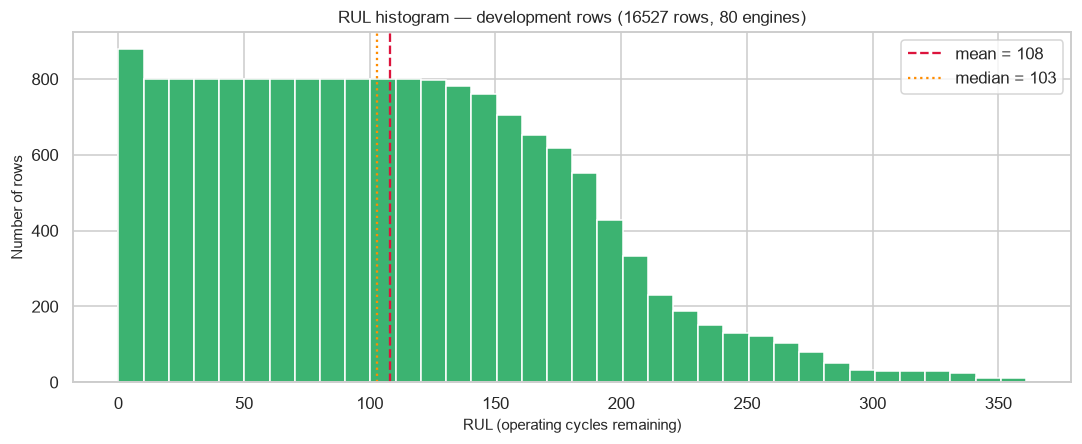

In [11]:
print(population_label("Development (80%)", dev))

dev_rul = dev["RUL"]
brackets = pd.DataFrame({
    "RUL range (cycles)": ["0–49", "50–99", "100–149", "150–199", "200–249", "250–299", "300–361"],
    "Rows": [int(dev_rul.between(0, 49).sum()), int(dev_rul.between(50, 99).sum()),
             int(dev_rul.between(100, 149).sum()), int(dev_rul.between(150, 199).sum()),
             int(dev_rul.between(200, 249).sum()), int(dev_rul.between(250, 299).sum()),
             int(dev_rul.between(300, 361).sum())],
})
brackets["Share of development rows"] = (brackets["Rows"] / len(dev_rul)).map("{:.1%}".format)
print("RUL stats — mean:", round(dev_rul.mean(), 1), "| median:", dev_rul.median(),
      "| std:", round(dev_rul.std(), 1), "| skewness:", round(dev_rul.skew(), 3),
      "| min:", int(dev_rul.min()), "| max:", int(dev_rul.max()))
display(brackets)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(dev_rul, bins=36, color="mediumseagreen", edgecolor="white")
ax.axvline(dev_rul.mean(), color="crimson", ls="--", lw=1.5, label=f"mean = {dev_rul.mean():.0f}")
ax.axvline(dev_rul.median(), color="darkorange", ls=":", lw=1.5, label=f"median = {dev_rul.median():.0f}")
ax.set_xlabel("RUL (operating cycles remaining)")
ax.set_ylabel("Number of rows")
ax.set_title(f"RUL histogram — development rows ({len(dev_rul)} rows, {dev['engine_id'].nunique()} engines)")
ax.legend()
plt.tight_layout()
plt.show()

**Reading of section E.** The row-level RUL distribution is **right-skewed** (skewness ≈ +0.52; mean 108.0 > median 103.0) with a long tail up to 361 cycles. Roughly **72% of development rows sit below RUL = 150** (0–49: 24.2%, 50–99: 24.2%, 100–149: 23.9%), while only ~3.2% of rows have RUL ≥ 250. Even so, the tail matters for error metrics: models that underpredict long remaining lives will be punished on exactly those rare rows. RUL values were **not capped or clipped** here; the maximum recorded value (361) is retained.

## F. Sensor trends for five example engines

**Purpose.** Sense-check how individual sensors behave over an engine's life. Five development engines are chosen **reproducibly and without regard to how their plots look**: the five lowest development engine IDs, by sorted order. Their IDs and lifetimes are printed below.

Sensors (names from the C-MAPSS sensor guide):

| Column | Meaning |
|---|---|
| `sensor_02` | T24 — total temperature at LPC outlet (degrees Rankine) |
| `sensor_03` | T30 — total temperature at HPC outlet (degrees Rankine) |
| `sensor_04` | T50 — total temperature at LPT outlet (degrees Rankine) |
| `sensor_07` | P30 — total pressure at HPC outlet (psia) |
| `sensor_11` | Ps30 — static pressure at HPC outlet (psia) |

Each sensor gets its own figure with two panels: reading vs cycle, and reading vs RUL with **failure at the right-hand side**. Raw readings are drawn faintly; a solid line adds a **trailing 20-cycle rolling mean** (past cycles only — no future information). The same engine colours are used in every figure.

[Development (80%)] engines: 80 | rows: 16527
Example engines chosen by rule 'five lowest development engine IDs': [1, 2, 3, 4, 5]
Their lifetimes (max recorded cycle): {1: 192, 2: 287, 3: 179, 4: 189, 5: 269}


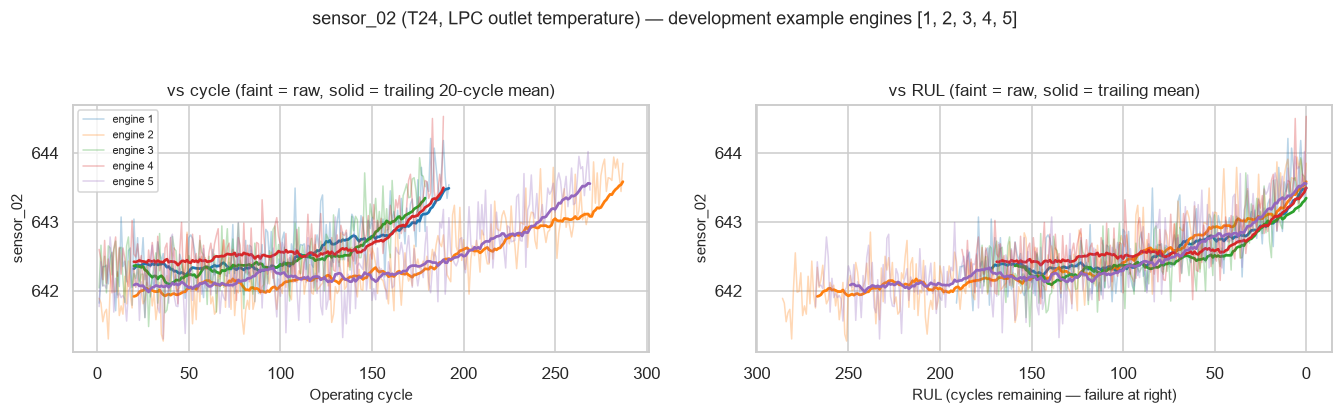

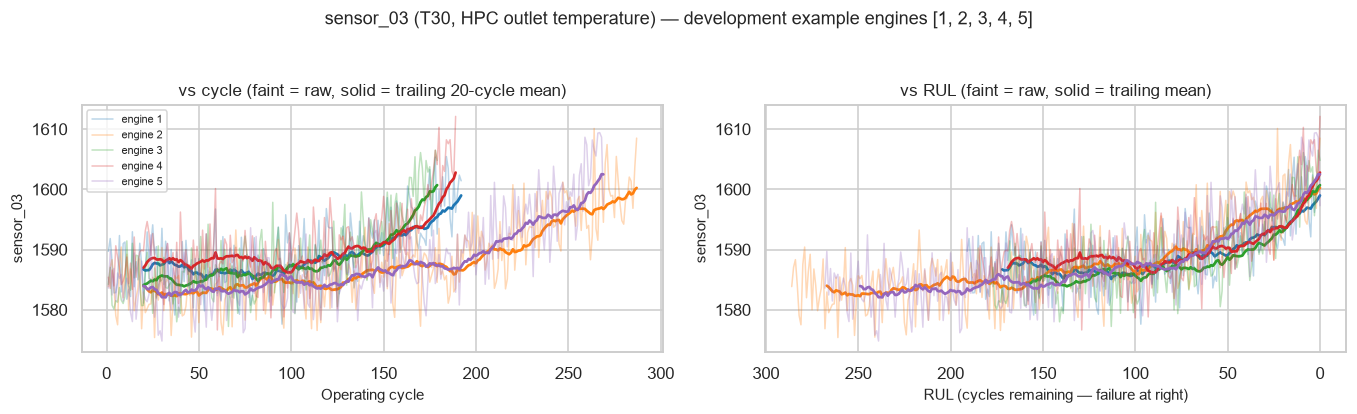

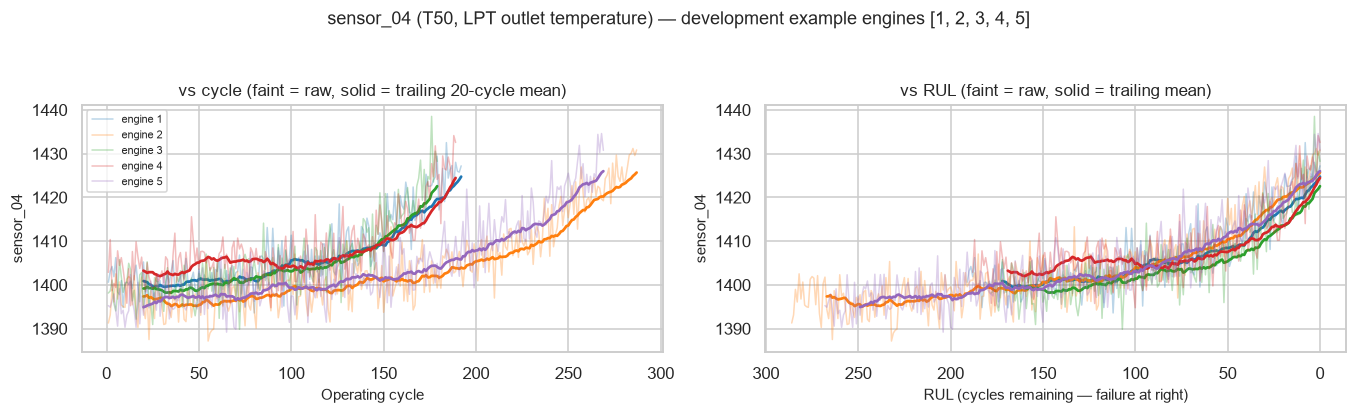

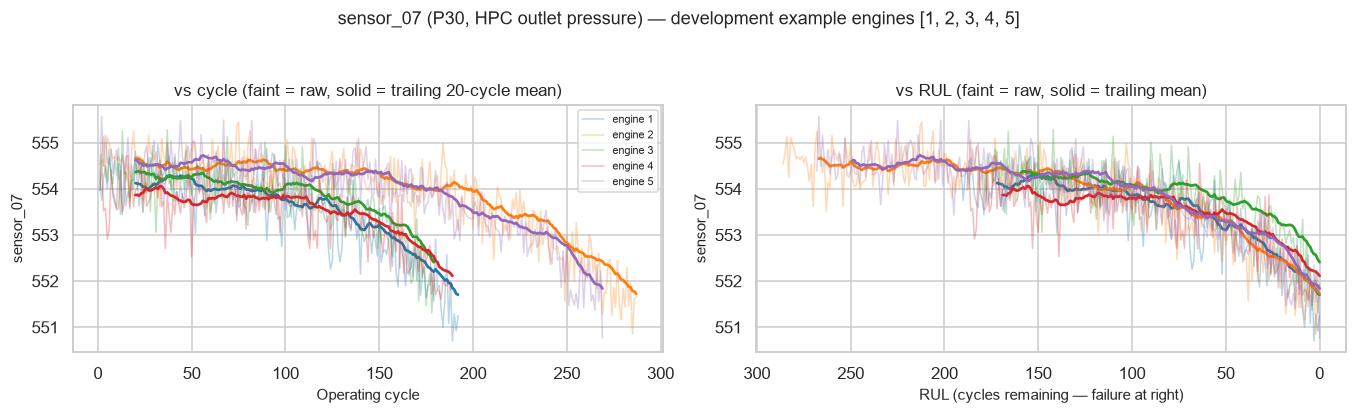

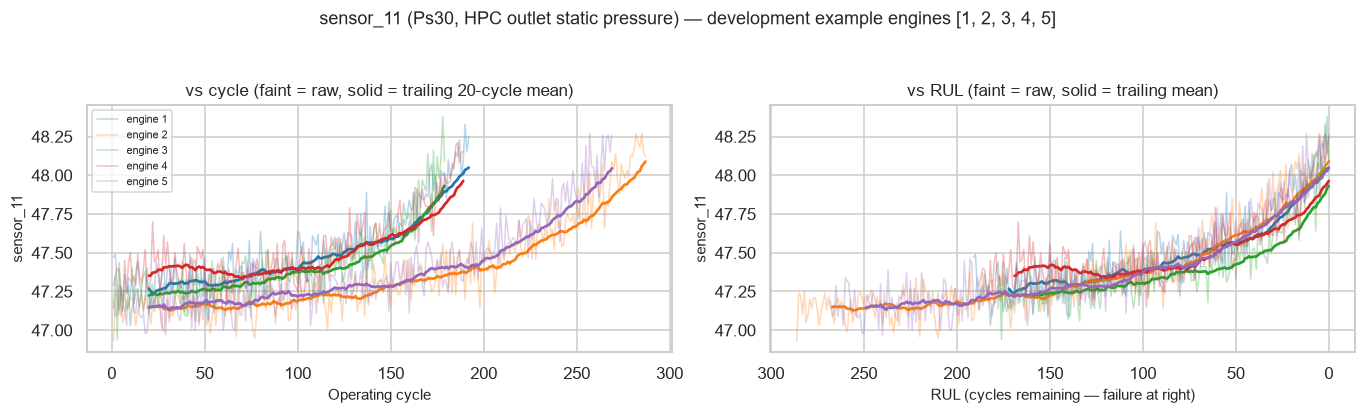

In [12]:
example_engines = [int(e) for e in sorted(dev_ids)[:5]]
example_sensors = ["sensor_02", "sensor_03", "sensor_04", "sensor_07", "sensor_11"]
sensor_titles = {
    "sensor_02": "sensor_02 (T24, LPC outlet temperature)",
    "sensor_03": "sensor_03 (T30, HPC outlet temperature)",
    "sensor_04": "sensor_04 (T50, LPT outlet temperature)",
    "sensor_07": "sensor_07 (P30, HPC outlet pressure)",
    "sensor_11": "sensor_11 (Ps30, HPC outlet static pressure)",
}
SMOOTH_WINDOW = 20

palette = plt.cm.tab10.colors
example_colors = {e: palette[i % len(palette)] for i, e in enumerate(example_engines)}

print(population_label("Development (80%)", dev))
print("Example engines chosen by rule 'five lowest development engine IDs':", example_engines)
print("Their lifetimes (max recorded cycle):",
      {int(e): int(dev_lifetime.loc[e]) for e in example_engines})

for s in example_sensors:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
    for e in example_engines:
        eng = dev.loc[dev["engine_id"] == e].sort_values("cycle")
        colour = example_colors[e]
        smoothed = eng[s].rolling(window=SMOOTH_WINDOW, min_periods=SMOOTH_WINDOW).mean()
        axes[0].plot(eng["cycle"], eng[s], color=colour, alpha=0.30, lw=1,
                     label=f"engine {e}")
        axes[0].plot(eng["cycle"], smoothed, color=colour, lw=1.8)
        axes[1].plot(eng["RUL"], eng[s], color=colour, alpha=0.30, lw=1)
        axes[1].plot(eng["RUL"], smoothed, color=colour, lw=1.8)
    axes[0].set_xlabel("Operating cycle")
    axes[0].set_ylabel(s)
    axes[0].set_title("vs cycle (faint = raw, solid = trailing 20-cycle mean)")
    axes[0].legend(fontsize=7, loc="best")
    axes[1].set_xlabel("RUL (cycles remaining — failure at right)")
    axes[1].set_ylabel(s)
    axes[1].set_title("vs RUL (faint = raw, solid = trailing mean)")
    axes[1].invert_xaxis()
    fig.suptitle(f"{sensor_titles[s]} — development example engines {example_engines}", y=1.04)
    plt.tight_layout()
    plt.show()

**Reading of section F.** In these five engines (IDs 1–5, lifetimes 179–287 cycles):

- `sensor_02`, `sensor_03`, `sensor_04` and `sensor_11` **generally rise** as the engine approaches failure (higher outlet temperatures, higher HPC static pressure).
- `sensor_07` **generally falls** towards failure (loss of HPC outlet pressure).
- None of the traces is strictly monotonic: all show cycle-to-cycle scatter and some mid-life reversals, and the level differs from engine to engine. Trends should therefore be treated as *tendencies with noise*, and any later features (e.g. rolling means) will smooth exactly this scatter. This is also why section H reports small but consistent average changes rather than claiming an always-monotonic behaviour.

## G. Sensor correlations and sensor–RUL relationships (development partition)

**Purpose.** Rank how strongly each sensor is associated with remaining life, and how strongly sensors overlap with each other. **Engine IDs, constant columns, and anything computed from future lifetime are excluded** from predictor-style comparisons.

Methods: Pearson (linear association) and Spearman (monotonic association, rank-based). Spearman is emphasised because the feature–target relationship in engine degradation is usually monotonic rather than strictly linear.

[Development (80%)] engines: 80 | rows: 16527
Sensors included (all nonconstant, including nearly constant sensor_06): ['sensor_02', 'sensor_03', 'sensor_04', 'sensor_06', 'sensor_07', 'sensor_08', 'sensor_09', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


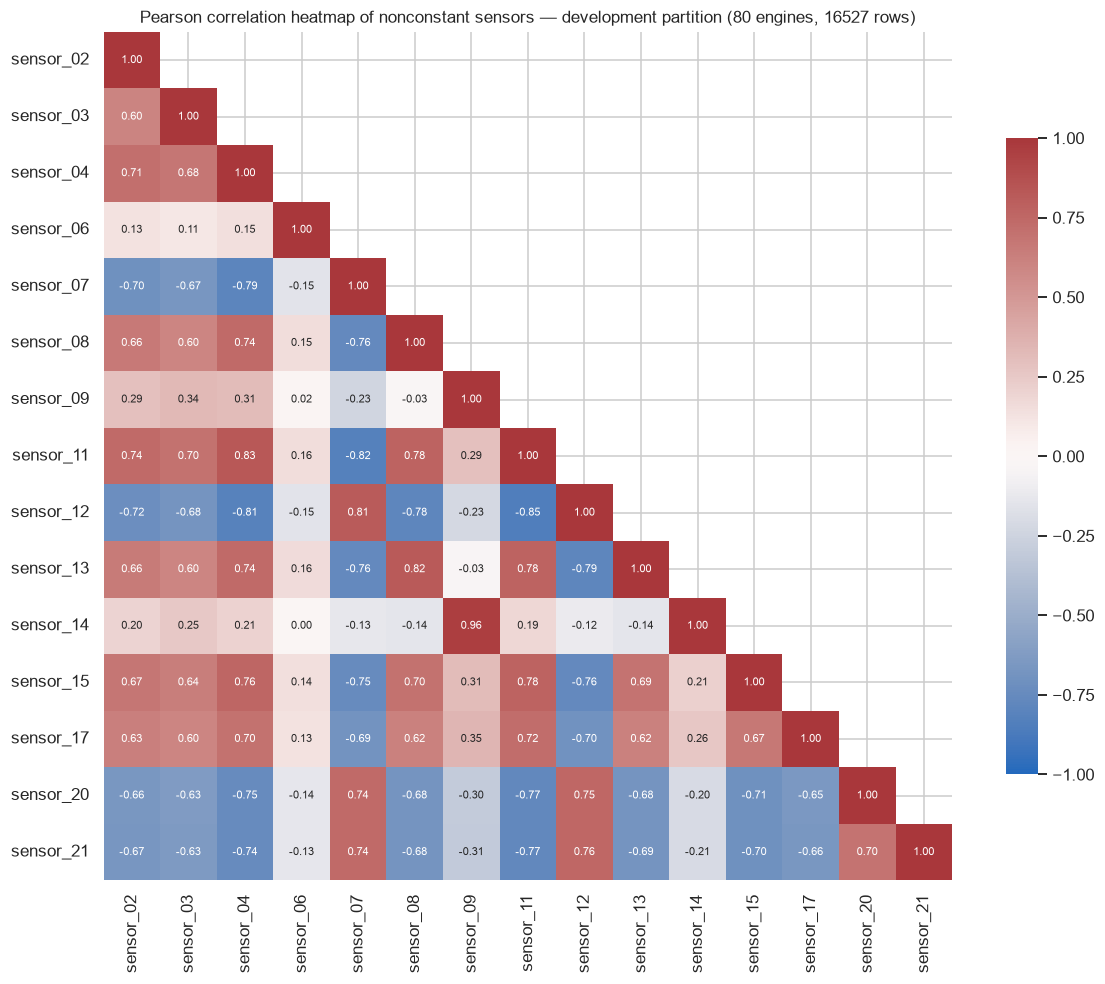

In [13]:
print(population_label("Development (80%)", dev))

sensor_cols = [c for c in nonconstant_inputs if c.startswith("sensor_")]
print("Sensors included (all nonconstant, including nearly constant sensor_06):", sensor_cols)

corr_matrix = dev[sensor_cols].corr(method="pearson")
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
            cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title(f"Pearson correlation heatmap of nonconstant sensors — development partition "
             f"({dev['engine_id'].nunique()} engines, {len(dev)} rows)")
plt.tight_layout()
plt.show()

In [14]:
sens_rul = pd.DataFrame({
    "Pearson r": dev[sensor_cols + ["RUL"]].corr(method="pearson")["RUL"].drop("RUL"),
    "Spearman rho": dev[sensor_cols + ["RUL"]].corr(method="spearman")["RUL"].drop("RUL"),
})
sens_rul["|Spearman|"] = sens_rul["Spearman rho"].abs()
sens_rul = sens_rul.sort_values("|Spearman|", ascending=False)
sens_rul.insert(0, "Rank by |Spearman|", range(1, len(sens_rul) + 1))
print("Sensor–RUL correlation table — development partition "
      f"({dev['engine_id'].nunique()} engines, {len(dev)} rows), signs retained:")
display(sens_rul.round(3))

top4_sensors = sens_rul.index[:4].tolist()
print("Four sensors with the strongest |Spearman| association with RUL:", top4_sensors)

Sensor–RUL correlation table — development partition (80 engines, 16527 rows), signs retained:


,Rank by |Spearman|,Pearson r,Spearman rho,|Spearman|
sensor_11,1,-0.691,-0.713,0.713
sensor_04,2,-0.674,-0.696,0.696
sensor_12,3,0.667,0.687,0.687
sensor_07,4,0.654,0.675,0.675
sensor_15,5,-0.640,-0.662,0.662
sensor_21,6,0.630,0.651,0.651
sensor_20,7,0.625,0.649,0.649
sensor_02,8,-0.602,-0.623,0.623
sensor_17,9,-0.600,-0.623,0.623
sensor_03,10,-0.583,-0.604,0.604


Four sensors with the strongest |Spearman| association with RUL: ['sensor_11', 'sensor_04', 'sensor_12', 'sensor_07']


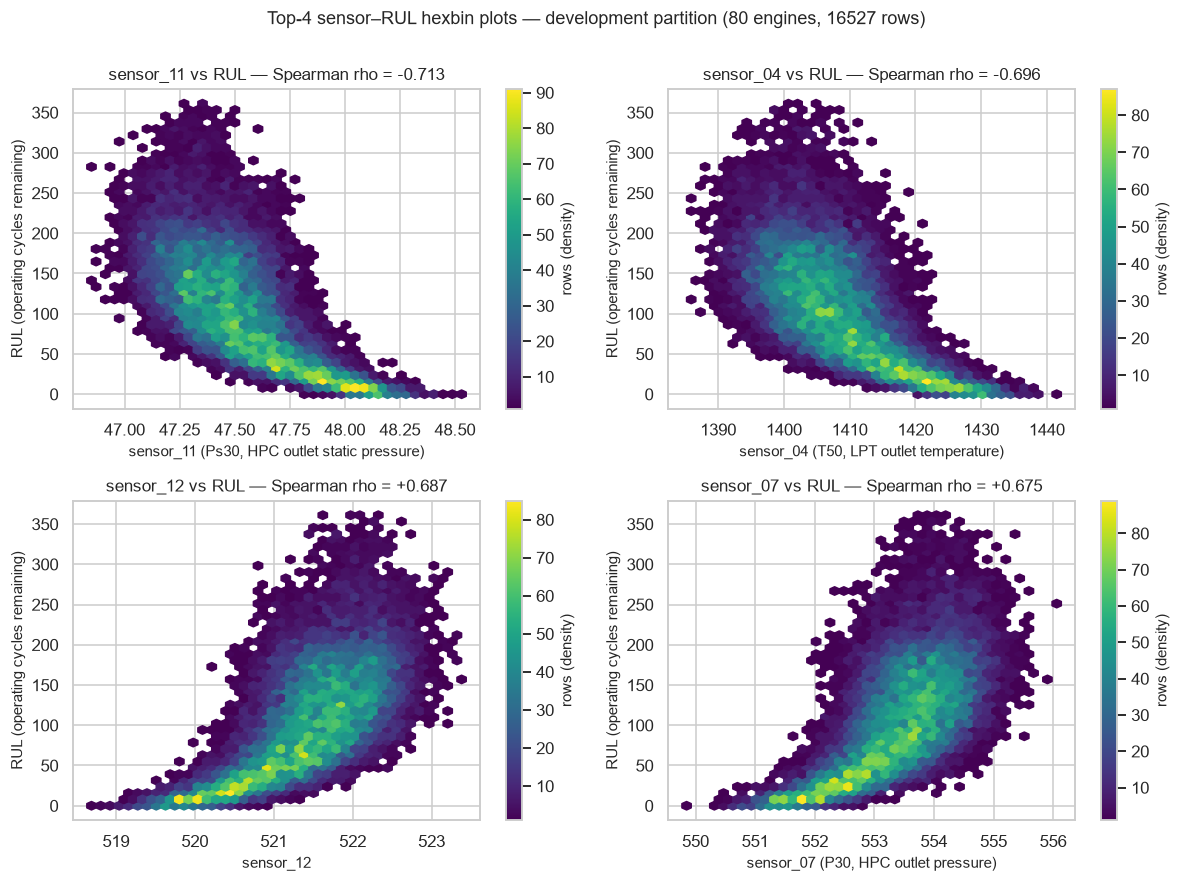

In [15]:
rho = sens_rul["Spearman rho"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, s in zip(axes.ravel(), top4_sensors):
    hb = ax.hexbin(dev[s], dev["RUL"], gridsize=40, cmap="viridis", mincnt=1)
    ax.set_xlabel(sensor_titles.get(s, s))
    ax.set_ylabel("RUL (operating cycles remaining)")
    ax.set_title(f"{s} vs RUL — Spearman rho = {rho[s]:+.3f}")
    fig.colorbar(hb, ax=ax, label="rows (density)")
fig.suptitle(f"Top-4 sensor–RUL hexbin plots — development partition "
             f"({dev['engine_id'].nunique()} engines, {len(dev)} rows)", y=1.0)
plt.tight_layout()
plt.show()

In [16]:
import itertools

pair_rows = []
for a, b in itertools.combinations(nonconstant_inputs, 2):
    rho_ab = dev[[a, b]].corr(method="spearman").iloc[0, 1]
    pair_rows.append({"Column A": a, "Column B": b, "Spearman rho": rho_ab})
pairs = pd.DataFrame(pair_rows)
pairs["|rho|"] = pairs["Spearman rho"].abs()
print("Five most strongly correlated pairs among nonconstant inputs (development partition):")
display(pairs.sort_values("|rho|", ascending=False).head(5).drop(columns="|rho|").round(3))

Five most strongly correlated pairs among nonconstant inputs (development partition):


,Column A,Column B,Spearman rho
120,sensor_09,sensor_14,0.889
125,sensor_11,sensor_12,-0.831
79,sensor_04,sensor_11,0.810
100,sensor_07,sensor_11,-0.804
111,sensor_08,sensor_13,0.803


**Reading of section G.**

- Strongest **sensor–RUL** associations are all monotonic and moderate: `sensor_11` (ρ = −0.713), `sensor_04` (ρ = −0.696), `sensor_12` (ρ = +0.687) and `sensor_07` (ρ = +0.675). Signs differ because some sensors *rise* toward failure (temperatures, `sensor_12`) while others *fall* (`sensor_07`, `sensor_11` vs RUL relationship is negative because `sensor_11` rises toward failure).
- Sensors overlap heavily: the strongest sensor pair in the table is `sensor_09`–`sensor_14` (ρ ≈ 0.889), followed by `sensor_11`–`sensor_12` (ρ ≈ −0.831), `sensor_04`–`sensor_11` (ρ ≈ 0.810) and `sensor_07`–`sensor_11` (ρ ≈ −0.804). Such groups carry partly **redundant information**; linear models may need selection or regularisation.
- Caveats that matter for interpretation:
  - Correlation is **association, not causation**.
  - A weak correlation does **not** prove a sensor is useless — it may matter only in combination with others or within specific engines. (Weakest in the table: `sensor_06` ρ ≈ −0.129 — and it is also the nearly constant column from section C, so its low rank is expected.)
  - Pooled correlations **mix within-engine change and between-engine differences** and can overstate or understate the within-engine signal.
  - These rankings are **exploratory**, computed on the development partition only; they are not final proof of predictive importance.
  - No p-values are reported: with repeated cycles per engine, ordinary row-level p-values would treat non-independent rows as independent.

## H. Early recorded life vs near failure (development partition)

**Purpose.** For each development engine, compare the mean sensor value over its **first 20 recorded cycles (“early recorded life”)** with its mean over its **final 20 recorded cycles (“near failure”)**. Because 20 + 20 = 40 cycles, engines need ≥ 40 recorded cycles for the two windows to be non-overlapping — verified below (minimum development lifetime is 128).

Every engine counts **once** in each summary (mean of its 20-cycle windows), so all engines get **equal weight**, unlike the row-level tables earlier. Uncertainty is quantified with a **bootstrap that resamples whole engine pairs** (2,000 resamples, seed 42) — never individual rows, because rows within an engine are not independent.

In [17]:
print(population_label("Development (80%)", dev))

WINDOW = 20
assert dev_lifetime.min() >= 2 * WINDOW, "Some engines are too short for non-overlapping windows"
print(f"Smallest development engine lifetime: {dev_lifetime.min()} cycles "
      f"(>= {2 * WINDOW} needed for non-overlapping windows) — verified.")

dev_sorted = dev.sort_values(["engine_id", "cycle"])
early_means = (dev_sorted.groupby("engine_id").head(WINDOW)
               .groupby("engine_id")[example_sensors].mean())
late_means = (dev_sorted.groupby("engine_id").tail(WINDOW)
              .groupby("engine_id")[example_sensors].mean())
change = late_means - early_means

boot_rng = np.random.default_rng(SEED)


def bootstrap_ci_mean(values, n_boot=2000):
    idx = boot_rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return np.percentile(means, 2.5), np.percentile(means, 97.5)


rows = []
for s in example_sensors:
    lo, hi = bootstrap_ci_mean(change[s].to_numpy())
    rows.append({
        "Sensor": s,
        "Engines": len(change),
        "Mean early (first 20 cycles)": early_means[s].mean(),
        "Mean late (last 20 cycles)": late_means[s].mean(),
        "Mean paired change": change[s].mean(),
        "Median paired change": change[s].median(),
        "95% bootstrap CI of mean change": f"[{lo:+.3f}, {hi:+.3f}]",
    })
comparison = pd.DataFrame(rows)
print("Early vs near-failure comparison — one pair per engine, equal engine weight:")
display(comparison.round(4))

[Development (80%)] engines: 80 | rows: 16527
Smallest development engine lifetime: 128 cycles (>= 40 needed for non-overlapping windows) — verified.
Early vs near-failure comparison — one pair per engine, equal engine weight:


,Sensor,Engines,Mean early (first 20 cycles),Mean late (last 20 cycles),Mean paired change,Median paired change,95% bootstrap CI of mean change
0,sensor_02,80,642.3722,643.4827,1.1105,1.1035,"[+1.064, +1.160]"
1,sensor_03,80,1586.7658,1600.1141,13.3484,13.2123,"[+12.820, +13.880]"
2,sensor_04,80,1402.6941,1424.9185,22.2244,22.0470,"[+21.309, +23.131]"
3,sensor_07,80,553.9555,551.8426,-2.1129,-2.1227,"[-2.215, -2.009]"
4,sensor_11,80,47.3490,48.0301,0.6812,0.6630,"[+0.652, +0.711]"


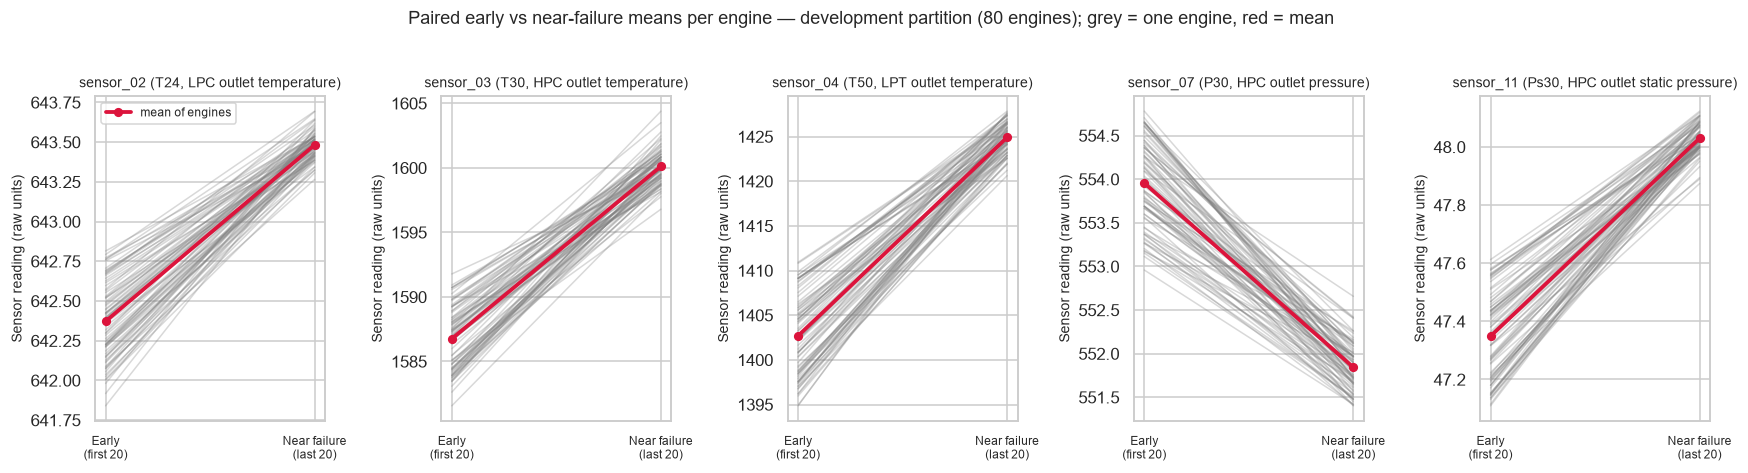

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4.2))
for ax, s in zip(axes, example_sensors):
    for e in change.index:
        ax.plot([0, 1], [early_means.loc[e, s], late_means.loc[e, s]],
                color="grey", alpha=0.30, lw=1)
    ax.plot([0, 1], [early_means[s].mean(), late_means[s].mean()],
            color="crimson", lw=2.5, marker="o", ms=5, label="mean of engines")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Early\n(first 20)", "Near failure\n(last 20)"], fontsize=8)
    ax.set_title(sensor_titles[s], fontsize=9)
    ax.set_ylabel("Sensor reading (raw units)", fontsize=9)
axes[0].legend(fontsize=8)
fig.suptitle(f"Paired early vs near-failure means per engine — development partition "
             f"({len(change)} engines); grey = one engine, red = mean", y=1.02)
plt.tight_layout()
plt.show()

**Reading of section H.** With 80 engines weighted equally:

| Sensor | Mean early | Mean near failure | Mean paired change | 95% bootstrap CI |
|---|---|---|---|---|
| `sensor_02` (T24) | 642.372 | 643.483 | **+1.111** | [+1.064, +1.160] |
| `sensor_03` (T30) | 1586.766 | 1600.114 | **+13.348** | [+12.820, +13.880] |
| `sensor_04` (T50) | 1402.694 | 1424.919 | **+22.224** | [+21.309, +23.131] |
| `sensor_07` (P30) | 553.956 | 551.843 | **−2.113** | [−2.215, −2.009] |
| `sensor_11` (Ps30) | 47.349 | 48.030 | **+0.681** | [+0.652, +0.711] |

All five intervals exclude zero, so the average shift between early life and near failure is consistent for every engine cohort — temperatures and static pressure rise, HPC outlet pressure falls. The grey lines show substantial engine-to-engine variation around those averages: the *direction* is consistent, but the *size* is not uniform. Remember these are **retrospective** summaries that use each engine's final cycles. Such information can never be supplied as a predictor for a genuinely new engine; it only tells us that these sensors carry a degradation signal worth exploiting with past-only features (rolling means, slopes, etc.) later.

## Findings summary

| Finding | Supporting evidence | Meaning for later modelling |
|---|---|---|
| The FD001 training file is clean and internally consistent | 20,631 rows / 100 engines / 27 numeric columns; 0 missing, 0 non-finite, 0 duplicate rows, 0 duplicate (engine, cycle) keys; every engine starts at cycle 1 with no gaps; RUL = max cycle − cycle exactly; final RUL = 0 for all engines | No cleaning required. The only pre-processing decisions concern constant columns and scaling |
| Seven columns are exactly constant; one more is nearly constant | Constant on development: `operating_setting_3`, `sensor_01`, `sensor_05`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`. `sensor_06` has 2 values, 21.61 in ≈ 98% of rows | Drop the seven constants; treat `sensor_06` as low-information and review before use. Original files are unchanged |
| Engines live very different lengths | Development lifetimes 128–362 cycles (mean ≈ 207, std ≈ 47, IQR ≈ 38) | Use engine-level splits (done: 80/20, seed 42) and cap window sizes well below 128 cycles; row-level splits would leak information |
| Row-level RUL is right-skewed and uncapped | Mean 108.0, median 103.0, skewness +0.52, range 0–361; ≈ 72% of rows below RUL 150, only ≈ 3% at or above 250 | Keep the raw target for now; error metrics will be dominated by the crowded low–mid RUL region. Whether to cap RUL in later experiments is a validation-time decision, not made here |
| Degradation signal is visible in the five example sensors | Engine-weighted mean changes early → near failure: T24 +1.11, T30 +13.35, T50 +22.22, P30 −2.11, Ps30 +0.68; all 95% bootstrap CIs exclude zero | Past-only trend features (rolling means/slopes over 20-cycle windows) are promising inputs for later models; expect noise, not monotonicity, at the row level |
| Strongest single-sensor associations with RUL are moderate | Spearman ρ: `sensor_11` −0.713, `sensor_04` −0.696, `sensor_12` +0.687, `sensor_07` +0.675 | Useful starting features, but no single sensor suffices; expect multivariate models to combine them |
| Sensors are strongly inter-correlated | Strongest pairs: `sensor_09`–`sensor_14` ρ ≈ 0.889, `sensor_11`–`sensor_12` ρ ≈ −0.831, `sensor_04`–`sensor_11` ρ ≈ 0.810 | Overlapping information — prefer regularised/linear models with selection or dimensionality awareness; avoid interpreting individual coefficients as physical causes |
| Monitoring split must not be reinterpreted as model quality | All statistics here are development-only; the 20 validation engines (4,104 rows) have simply been reserved | Final model selection and honest performance estimates happen later on the untouched validation partition and the official test files |

## Limitations

- **Simulated data:** C-MAPSS FD001 is a simulator output with one operating condition and one (HPC) degradation mode. Findings do not automatically transfer to real fleets.
- **Repeated observations:** 20,631 rows come from only 100 engines; rows are not independent, which is why all engine-level comparisons use paired engine summaries and engine-level bootstrap.
- **Limited scope:** FD002–FD004 have different conditions/degradation modes and were deliberately not merged here.
- **Recorded length ≠ real age:** lifetimes describe observed simulation trajectories, not engines' true age since manufacture.
- **Correlations are exploratory:** pooled correlations blend within-engine change and between-engine variation, and are computed on the development partition only.
- **Documentation gaps:** `README.md` is empty (0 bytes) and `NASA_CMAPSS_RUL_Supervised_Regression_Project_Proposal.pdf` was not found; the notebook therefore relies on `data_dictionary.csv`, `validation_summary.csv` and the sensor guide PDF that is present.
- **Official test files untouched:** `test_FD001.csv`, `RUL_FD001.csv` and `test_last_cycle_FD001_labeled.csv` were not opened and remain reserved for final evaluation.

## Final verification

This cell re-checks the commitments made at the start: only the training file and documentation were read, development/validation engines do not overlap, and the official test files are still present and untouched.

In [21]:
official_test_files = ["test_FD001.csv", "RUL_FD001.csv", "test_last_cycle_FD001_labeled.csv"]

print("Files actually read by this notebook:", FILES_USED)
assert not any("test" in name.lower() for name in FILES_USED), "A test file was opened!"
print("Official test files used: NONE")

assert all((DATA_DIR / name).is_file() for name in official_test_files)
print("Official test files still present, untouched:", official_test_files)

assert set(dev_ids).isdisjoint(set(val_ids))
assert len(set(dev_ids) | set(val_ids)) == 100
print(f"Development engines: {len(dev_ids)} | validation engines: {len(val_ids)} "
      f"| overlap: none | total covered: 100")

assert len(dev) + len(val) == len(train)
print(f"Rows accounted for: {len(dev)} (development) + {len(val)} (validation) = {len(train)} "
      "(full training file)")

print("Seed used for the split and bootstrap:", SEED)
print("All verification checks passed.")

Files actually read by this notebook: ['train_FD001.csv', 'data_dictionary.csv', 'validation_summary.csv']
Official test files used: NONE
Official test files still present, untouched: ['test_FD001.csv', 'RUL_FD001.csv', 'test_last_cycle_FD001_labeled.csv']
Development engines: 80 | validation engines: 20 | overlap: none | total covered: 100
Rows accounted for: 16527 (development) + 4104 (validation) = 20631 (full training file)
Seed used for the split and bootstrap: 42
All verification checks passed.
